# Árboles

**Matemática Discreta (2026/27)** · Edgar Martínez-Moro · Departamento de Matemática Aplicada, Escuela de Ingeniería Informática, Universidad de Valladolid

Este cuaderno acompaña a la sesión 18 del tema de **teoría de grafos**. Contiene:

1. Árboles y bosques: comprobaciones con los teoremas 4.64 y 4.65.
2. Árbol generador por recorrido en anchura.
3. Árbol generador mínimo: Kruskal (constructivo y destructivo) y Prim.
4. Árboles con raíz: niveles, altura, $m$-arios, regulares y plenos.
5. Recorridos en preorden, postorden e inorden.

## Repaso

Un **árbol** es un grafo conexo y acíclico; un **bosque**, un grafo acíclico. Un árbol con $n$ vértices tiene $n-1$ aristas, y con $n$ vértices son equivalentes ser árbol, ser conexo con $n-1$ aristas y ser acíclico con $n-1$ aristas.

Un **árbol generador** de un grafo conexo es un subgrafo parcial que es árbol; en un grafo pesado, el **mínimo** es el de menor suma de pesos.

Para dibujar los grafos usamos una función sencilla con `matplotlib`: las posiciones de los vértices se dan a mano.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch



def dibujar(pos, aristas, dirigido=False, pesos=None, resaltar=(), titulo=None,
            tam=(4, 3), radio=0.22):
    """
    pos: {vértice: (x, y)}; aristas: lista de pares (o de ternas con peso).
    Las aristas repetidas se dibujan curvadas; los lazos, como un pequeño círculo.
    resaltar: aristas que se pintan en rojo.
    """
    fig, ax = plt.subplots(figsize=tam)
    resaltar = {frozenset(a[:2]) for a in resaltar} if not dirigido else {tuple(a[:2]) for a in resaltar}
    vistas, total = {}, {}
    for a in aristas:
        clave = (a[0], a[1]) if dirigido else frozenset((a[0], a[1]))
        total[clave] = total.get(clave, 0) + 1
    for a in aristas:
        x, y = a[0], a[1]
        if not dirigido and str(x) > str(y):
            x, y = y, x                      # mismo sentido para curvar las múltiples
        w = a[2] if len(a) > 2 else None
        clave = (x, y) if dirigido else frozenset((x, y))
        k = vistas.get(clave, 0)
        vistas[clave] = k + 1
        rojo = (clave in resaltar)
        color = "darkred" if rojo else "teal"
        lw = 2.4 if rojo else 1.4
        if x == y:
            cx, cy = pos[x]
            ax.add_patch(plt.Circle((cx, cy - radio * 1.2), radio * 0.9, fill=False, color=color, lw=lw))
            continue
        t = total[clave]
        curva = 0.3 * (k - (t - 1) / 2) if t > 1 else 0.0
        if dirigido and (y, x) in [tuple(b[:2]) for b in aristas]:
            curva = 0.2
        flecha = FancyArrowPatch(pos[x], pos[y], connectionstyle=f"arc3,rad={curva}",
                                 arrowstyle="-|>" if dirigido else "-", mutation_scale=14,
                                 color=color, lw=lw, shrinkA=9, shrinkB=9)
        ax.add_patch(flecha)
        if w is not None or (pesos and clave in pesos):
            w = w if w is not None else pesos[clave]
            (x1, y1), (x2, y2) = pos[x], pos[y]
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(w), fontsize=8, ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    for v, (x, y) in pos.items():
        ax.text(x, y, str(v), ha="center", va="center", fontsize=9, zorder=3,
                bbox=dict(boxstyle="circle,pad=0.3", fc="#e6f2f2", ec="teal"))
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    ax.set_ylim(min(ys) - 0.6, max(ys) + 0.6)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if titulo:
        ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()
    return fig

In [2]:
from collections import deque
import random, time

## 1. Árboles y bosques

In [3]:
def componentes(vertices, aristas):
    vec = {x: set() for x in vertices}
    for a, b in aristas:
        vec[a].add(b)
        vec[b].add(a)
    visto, comps = set(), []
    for s in vertices:
        if s not in visto:
            comp, pila = [], [s]
            visto.add(s)
            while pila:
                x = pila.pop()
                comp.append(x)
                for y in vec[x] - visto:
                    visto.add(y)
                    pila.append(y)
            comps.append(comp)
    return comps


def es_bosque(vertices, aristas):
    """Acíclico <=> |A| = |V| - (número de componentes)  (lema 4.64)."""
    return len(aristas) == len(vertices) - len(componentes(vertices, aristas))


def es_arbol(vertices, aristas):
    """Conexo y con n - 1 aristas (teorema 4.65)."""
    return len(componentes(vertices, aristas)) == 1 and len(aristas) == len(vertices) - 1


def hojas(vertices, aristas):
    g = {x: 0 for x in vertices}
    for a, b in aristas:
        g[a] += 1
        g[b] += 1
    return [x for x in vertices if g[x] == 1]

In [4]:
Va = list(range(1, 10))
arbol = [(1, 2), (2, 3), (3, 7), (2, 5), (5, 9), (2, 4), (3, 6), (1, 8)]
print(es_arbol(Va, arbol), es_bosque(Va, arbol), hojas(Va, arbol))
print(es_arbol(Va, arbol + [(4, 5)]), es_bosque(Va, arbol + [(4, 5)]))   # se forma un ciclo
print(es_arbol(Va, arbol[:-1]), es_bosque(Va, arbol[:-1]))                # dos componentes

True True [4, 6, 7, 8, 9]
False False
False True


Las comprobaciones usan el lema 4.64: un grafo con $n$ vértices y $m$ componentes conexas es un bosque si y sólo si tiene $n-m$ aristas.

## 2. Árbol generador por recorrido en anchura

Sin pesos, cualquier recorrido da un árbol generador: cada vez que se llega a un vértice nuevo, la arista usada entra en el árbol (observación 4.70 d).

In [5]:
def arbol_generador_anchura(vertices, aristas, raiz=None):
    """Árbol generador de un grafo conexo (sin pesos): recorrido en anchura."""
    vec = {x: [] for x in vertices}
    for a, b in aristas:
        vec[a].append(b)
        vec[b].append(a)
    raiz = vertices[0] if raiz is None else raiz
    visto, cola, arbol = {raiz}, deque([raiz]), []
    while cola:
        x = cola.popleft()
        for y in vec[x]:
            if y not in visto:
                visto.add(y)
                arbol.append((x, y))
                cola.append(y)
    return arbol

[('x1', 'x2'), ('x1', 'x4'), ('x2', 'x3'), ('x2', 'x6'), ('x4', 'x5'), ('x3', 'x7')] True


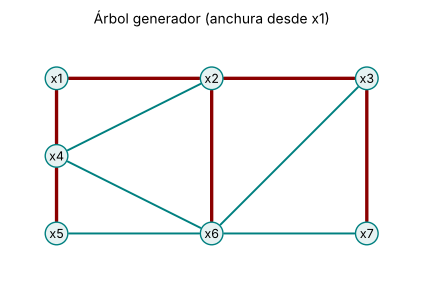

In [6]:
V = ["x1", "x2", "x3", "x4", "x5", "x6", "x7"]
A = [("x1", "x2", 5), ("x2", "x3", 5), ("x1", "x4", 5), ("x2", "x4", 5), ("x2", "x6", 3),
     ("x4", "x6", 3), ("x3", "x6", 4), ("x3", "x7", 2), ("x4", "x5", 3), ("x5", "x6", 1), ("x6", "x7", 5)]
A0 = [(x, y) for x, y, _ in A]
pos = {"x1": (0, 2), "x2": (2, 2), "x3": (4, 2), "x4": (0, 1), "x5": (0, 0), "x6": (2, 0), "x7": (4, 0)}
T = arbol_generador_anchura(V, A0, "x1")
print(T, es_arbol(V, T))
dibujar(pos, A0, resaltar=T, titulo="Árbol generador (anchura desde x1)", tam=(5, 3));

## 3. Árbol generador mínimo

### Kruskal constructivo

Se ordenan las aristas por peso y se añade cada una si no forma ciclo. Para saber si forma ciclo usamos la **unión-búsqueda** de la sesión 12: forma ciclo si sus extremos ya están en la misma componente.

In [7]:
def kruskal(vertices, aristas, traza=False):
    """
    Kruskal constructivo: se ordenan las aristas por peso y se añade cada una
    si no forma ciclo, hasta tener n - 1. Para saber si forma ciclo se usa
    la unión-búsqueda de la sesión 12: forma ciclo si sus extremos ya
    están en la misma componente.
    aristas: lista de (x, y, peso).
    """
    padre = {x: x for x in vertices}

    def raiz(x):
        while padre[x] != x:
            padre[x] = padre[padre[x]]
            x = padre[x]
        return x

    arbol = []
    for x, y, w in sorted(aristas, key=lambda a: (a[2], str(a[0]), str(a[1]))):
        rx, ry = raiz(x), raiz(y)
        if rx != ry:
            padre[ry] = rx
            arbol.append((x, y, w))
            if traza:
                print(f"  paso {len(arbol)}: añade {{{x},{y}}}  peso {w}")
            if len(arbol) == len(vertices) - 1:
                break
        elif traza:
            print(f"          descarta {{{x},{y}}} peso {w}: formaría un ciclo")
    return arbol


def peso(arbol):
    return sum(w for _, _, w in arbol)

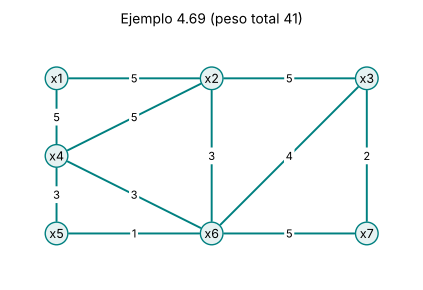

  paso 1: añade {x5,x6}  peso 1
  paso 2: añade {x3,x7}  peso 2
  paso 3: añade {x2,x6}  peso 3
  paso 4: añade {x4,x5}  peso 3
          descarta {x4,x6} peso 3: formaría un ciclo
  paso 5: añade {x3,x6}  peso 4
  paso 6: añade {x1,x2}  peso 5
peso: 18


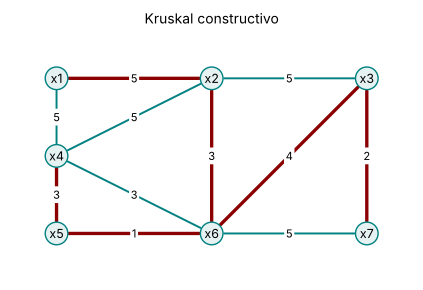

In [8]:
dibujar(pos, A, titulo="Ejemplo 4.69 (peso total 41)", tam=(5, 3))
T = kruskal(V, A, traza=True)
print("peso:", peso(T))
dibujar(pos, A, resaltar=T, titulo="Kruskal constructivo", tam=(5, 3));

En el último paso hay cinco aristas de peso $5$ y el programa desempata por orden alfabético: toma $\{x_1,x_2\}$, mientras que en clase se tomó $\{x_4,x_1\}$. Los dos árboles pesan $18$: el árbol generador mínimo no es único (observación 4.70 a).

### Kruskal destructivo

Se recorren las aristas de mayor a menor peso y se quita cada una si el grafo sigue conexo sin ella.

In [9]:
def kruskal_destructivo(vertices, aristas, traza=False):
    """
    Versión dual: se recorren las aristas de mayor a menor peso y se quita
    cada una si el grafo sigue conexo sin ella.
    """
    resto = list(aristas)
    paso = 0
    for a in sorted(aristas, key=lambda a: (-a[2], str(a[0]), str(a[1]))):
        if len(resto) == len(vertices) - 1:
            break
        prueba = [b for b in resto if b != a]
        if len(componentes(vertices, [(x, y) for x, y, _ in prueba])) == 1:
            resto = prueba
            paso += 1
            if traza:
                print(f"  paso {paso}: quita {{{a[0]},{a[1]}}}  peso {a[2]}")
        elif traza:
            print(f"          mantiene {{{a[0]},{a[1]}}} peso {a[2]}: desconectaría")
    return resto

  paso 1: quita {x1,x2}  peso 5
          mantiene {x1,x4} peso 5: desconectaría
  paso 2: quita {x2,x3}  peso 5
  paso 3: quita {x2,x4}  peso 5
  paso 4: quita {x6,x7}  peso 5
          mantiene {x3,x6} peso 4: desconectaría
          mantiene {x2,x6} peso 3: desconectaría
  paso 5: quita {x4,x5}  peso 3
peso: 18


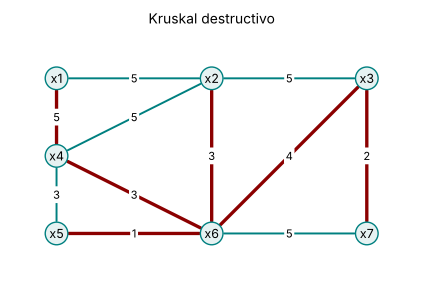

In [10]:
T2 = kruskal_destructivo(V, A, traza=True)
print("peso:", peso(T2))
dibujar(pos, A, resaltar=T2, titulo="Kruskal destructivo", tam=(5, 3));

### Prim

Desde un vértice, se añade en cada paso la arista de menor peso que une un vértice visitado con uno sin visitar.

In [11]:
def prim(vertices, aristas, inicio=None, traza=False):
    """
    Prim: desde un vértice, añadir en cada paso la arista de menor peso que
    une un vértice visitado con uno sin visitar.
    """
    inicio = vertices[0] if inicio is None else inicio
    visitados, arbol = {inicio}, []
    if traza:
        print(f"  inicio: {inicio}")
    while len(visitados) < len(vertices):
        candidatas = [(w, x, y) if x in visitados else (w, y, x)
                      for x, y, w in aristas if (x in visitados) != (y in visitados)]
        w, x, y = min(candidatas, key=lambda c: (c[0], str(c[1]), str(c[2])))
        visitados.add(y)
        arbol.append((x, y, w))
        if traza:
            print(f"  visita {y} por {{{x},{y}}}  peso {w}")
    return arbol

In [12]:
T3 = prim(V, A, "x2", traza=True)
print("peso:", peso(T3))

  inicio: x2
  visita x6 por {x2,x6}  peso 3
  visita x5 por {x6,x5}  peso 1
  visita x4 por {x5,x4}  peso 3
  visita x3 por {x6,x3}  peso 4
  visita x7 por {x3,x7}  peso 2
  visita x1 por {x2,x1}  peso 5
peso: 18


### Comprobación por fuerza bruta

Generamos todos los subconjuntos de $6$ aristas, nos quedamos con los árboles y buscamos el de menor peso.

In [13]:
from itertools import combinations
arboles = [S for S in combinations(A, 6) if es_arbol(V, [(x, y) for x, y, _ in S])]
minimo = min(peso(S) for S in arboles)
print(len(arboles), "árboles generadores;", "peso mínimo", minimo,
      "; árboles mínimos:", sum(peso(S) == minimo for S in arboles))

141 árboles generadores; peso mínimo 18 ; árboles mínimos: 4


### Comparación de tiempos

Kruskal con unión-búsqueda cuesta del orden de $|A|\log|A|$ (ordenar las aristas). Prim, tal como está escrito, revisa todas las aristas en cada paso: del orden de $|V|\cdot|A|$. El destructivo comprueba la conexión cada vez que quita una arista.

In [14]:
random.seed(2026)
for n in (50, 100, 200):
    Vn = list(range(n))
    An = [(i, i + 1, random.randint(1, 50)) for i in range(n - 1)]          # asegura conexión
    An += [(i, j, random.randint(1, 50)) for i in range(n) for j in range(i + 2, n) if random.random() < 6 / n]
    t0 = time.perf_counter(); a = kruskal(Vn, An)
    t1 = time.perf_counter(); b = prim(Vn, An, 0)
    t2 = time.perf_counter(); d = kruskal_destructivo(Vn, An)
    t3 = time.perf_counter()
    assert peso(a) == peso(b) == peso(d)
    print(f"n = {n:>3}, {len(An):>4} aristas: Kruskal {t1 - t0:.4f} s | Prim {t2 - t1:.3f} s | destructivo {t3 - t2:.3f} s")

n =  50,  181 aristas: Kruskal 0.0001 s | Prim 0.001 s | destructivo 0.006 s
n = 100,  412 aristas: Kruskal 0.0003 s | Prim 0.005 s | destructivo 0.028 s


n = 200,  788 aristas: Kruskal 0.0013 s | Prim 0.018 s | destructivo 0.111 s


## 4. Árboles con raíz

Un árbol con raíz se guarda como un diccionario: cada vértice, con la lista **ordenada** de sus hijos. El nivel (o altura) de un vértice es la longitud del camino desde la raíz.

In [15]:
def raiz_de(hijos):
    todos_hijos = {h for hs in hijos.values() for h in hs}
    raices = [x for x in hijos if x not in todos_hijos]
    if len(raices) != 1:
        raise ValueError("No es un árbol con raíz: hay %d raíces" % len(raices))
    return raices[0]


def niveles_arbol(hijos):
    """Nivel (altura) de cada vértice: longitud del camino desde la raíz."""
    r = raiz_de(hijos)
    nivel, cola = {r: 0}, deque([r])
    while cola:
        x = cola.popleft()
        for h in hijos.get(x, []):
            nivel[h] = nivel[x] + 1
            cola.append(h)
    return nivel


def altura(hijos):
    return max(niveles_arbol(hijos).values())


def tipo_de_arbol(hijos):
    """m (máximo exgrado), si es regular y si es pleno (definición 4.78)."""
    nivel = niveles_arbol(hijos)
    exg = [len(hijos.get(x, [])) for x in nivel]
    internos = [g for g in exg if g > 0]
    m = max(exg)
    regular = len(set(internos)) <= 1
    hojas_nivel = {nivel[x] for x in nivel if not hijos.get(x)}
    return {"m-ario con m =": m, "regular": regular,
            "pleno": regular and len(hojas_nivel) == 1}


def es_arbol_con_raiz(vertices, arcos):
    """Teorema 4.77 c): conexo, un vértice con ingrado 0 y los demás con ingrado 1."""
    ing = {x: 0 for x in vertices}
    for a, b in arcos:
        ing[b] += 1
    ceros = [x for x in vertices if ing[x] == 0]
    return (len(componentes(vertices, arcos)) == 1 and len(ceros) == 1
            and all(ing[x] == 1 for x in vertices if x not in ceros))

In [16]:
A1 = {"a": ["b", "c"], "b": ["d", "e", "f"], "c": ["g", "h"], "h": ["k", "m", "n", "p"]}
A2 = {"r": ["q", "u"], "q": ["s", "t"], "t": ["x", "v"]}
A3 = {"y": ["n", "z"], "n": ["m", "p"], "z": ["q", "a"], "m": ["k", "h"],
      "p": ["g", "f"], "q": ["e", "d"], "a": ["c", "b"]}
for nombre, H in (("cuaternario", A1), ("binario regular", A2), ("binario pleno", A3)):
    print(f"{nombre:<16} altura {altura(H)}  {tipo_de_arbol(H)}")

cuaternario      altura 3  {'m-ario con m =': 4, 'regular': False, 'pleno': False}
binario regular  altura 3  {'m-ario con m =': 2, 'regular': True, 'pleno': False}
binario pleno    altura 3  {'m-ario con m =': 2, 'regular': True, 'pleno': True}


In [17]:
# teorema 4.77 c): conexo, una raíz con ingrado 0 y los demás con ingrado 1
arcos = [("a", "b"), ("a", "c"), ("a", "d"), ("b", "e"), ("b", "f"), ("d", "g"), ("d", "h"), ("d", "i")]
print(es_arbol_con_raiz(list("abcdefghi"), arcos))
print(es_arbol_con_raiz(list("abcdefghi"), arcos[:-1] + [("i", "d")]))   # i y a, dos raíces

True
False


## 5. Recorridos en profundidad

- **Preorden:** la raíz y luego los subárboles de izquierda a derecha.
- **Postorden:** los subárboles de izquierda a derecha y luego la raíz.
- **Inorden** (árboles binarios regulares): el subárbol izquierdo, la raíz y el subárbol derecho.

In [18]:
def preorden(hijos, x=None):
    """Primero la raíz, luego los subárboles de izquierda a derecha."""
    x = raiz_de(hijos) if x is None else x
    lista = [x]
    for h in hijos.get(x, []):
        lista += preorden(hijos, h)
    return lista


def postorden(hijos, x=None):
    """Primero los subárboles de izquierda a derecha, luego la raíz."""
    x = raiz_de(hijos) if x is None else x
    lista = []
    for h in hijos.get(x, []):
        lista += postorden(hijos, h)
    return lista + [x]


def inorden(hijos, x=None):
    """Árboles binarios: subárbol izquierdo, raíz, subárbol derecho."""
    x = raiz_de(hijos) if x is None else x
    hs = hijos.get(x, [])
    if not hs:
        return [x]
    if len(hs) != 2:
        raise ValueError(f"inorden necesita un árbol binario regular ({x} tiene {len(hs)} hijos)")
    return inorden(hijos, hs[0]) + [x] + inorden(hijos, hs[1])

In [19]:
H = {"r": ["v", "s"], "v": ["u", "w"], "w": ["x", "y", "z"], "s": ["p", "q"]}
print("preorden: ", "".join(preorden(H)))
print("postorden:", "".join(postorden(H)))
B = {"r": ["v", "s"], "v": ["u", "w"], "w": ["x", "y"], "s": ["p", "q"], "q": ["m", "n"]}
print("inorden:  ", "".join(inorden(B)))

preorden:  rvuwxyzspq
postorden: uxyzwvpqsr
inorden:   uvxwyrpsmqn


### Árboles de expresiones

En un árbol de una expresión aritmética, las hojas son números y los vértices internos, operaciones. El inorden da la expresión habitual (le faltan los paréntesis, que habría que poner alrededor de cada subárbol), el preorden la notación polaca y el postorden la polaca inversa. Estas dos no necesitan paréntesis, y la polaca inversa se evalúa con una pila.

In [20]:
# (3 + 4) * (5 - 2)
E = {"*": ["+", "-"], "+": ["3", "4"], "-": ["5", "2"]}
print("inorden:  ", " ".join(inorden(E)))
print("preorden: ", " ".join(preorden(E)))
print("postorden:", " ".join(postorden(E)))

def evaluar_postorden(simbolos):
    pila = []
    for s in simbolos:
        if s in "+-*/":
            b, a = pila.pop(), pila.pop()
            pila.append({"+": a + b, "-": a - b, "*": a * b, "/": a / b}[s])
        else:
            pila.append(int(s))
    return pila[0]

print("valor:", evaluar_postorden(postorden(E)))

inorden:   3 + 4 * 5 - 2
preorden:  * + 3 4 - 5 2
postorden: 3 4 + 5 2 - *
valor: 21


Las etiquetas de los vértices tienen que ser distintas: si la expresión repite un número u operación, hay que dar a cada vértice un nombre propio.

## Referencias

- Kruskal, J. B. (1956). On the shortest spanning subtree of a graph and the traveling salesman problem. *Proceedings of the American Mathematical Society*, 7(1), 48–50.
- Prim, R. C. (1957). Shortest connection networks and some generalizations. *Bell System Technical Journal*, 36(6), 1389–1401.
- Grimaldi, R. P. (1998). *Matemática discreta y combinatoria* (3ª ed.). Addison Wesley Longman. Capítulos 12 y 13.